# Notebook 02 – Xử lý chất lượng dữ liệu và chuẩn bị dữ liệu cho mô hình
Thứ tự bắt buộc: **chia tập trước**, sau đó mọi phép biến đổi có "học" từ dữ liệu (điền thiếu, chuẩn hóa) chỉ được khớp (fit) trên tập huấn luyện.
Mã chia tập và Pipeline nằm trong `src/data.py` và `src/preprocess.py` để các notebook sau dùng lại đúng cách làm này.
Chạy notebook từ thư mục `notebooks/`.

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from data import NUM, CAT, TARGET, SEED, load_raw, split
from preprocess import build_preprocessor

FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

df = load_raw()
train, test = split()      # phân tầng theo origin, gom theo name, random_state = 42
df.shape, train.shape, test.shape

ModuleNotFoundError: No module named 'numpy'

## 1. Chia tập huấn luyện / kiểm tra

In [ ]:
rows = []
for ten, t in [("Huấn luyện", train), ("Kiểm tra", test)]:
    o = t["origin"].value_counts(normalize=True) * 100
    rows.append({"Tập": ten, "Số mẫu": len(t), "Tỷ lệ": f"{len(t) / len(df) * 100:.1f}%",
                 "usa %": round(o["usa"], 1), "japan %": round(o["japan"], 1), "europe %": round(o["europe"], 1),
                 "Năm TB": round(t["model_year"].mean(), 2), "MPG TB": round(t["mpg"].mean(), 2),
                 "Thiếu horsepower": int(t["horsepower"].isna().sum())})
display(pd.DataFrame(rows))

assert len(train) + len(test) == len(df)
shared = set(train["name"]) & set(test["name"])
assert not shared, "còn tên xe nằm ở cả hai tập"
print("Tên xe nằm ở cả hai tập:", len(shared), "| dòng lặp tên trong dữ liệu gốc:", int(df["name"].duplicated().sum()))
print("Xe 3 hoặc 5 xi-lanh: huấn luyện", int(train["cylinders"].isin([3, 5]).sum()), "| kiểm tra", int(test["cylinders"].isin([3, 5]).sum()))

,Tập,Số mẫu,Tỷ lệ,usa %,japan %,europe %,Năm TB,MPG TB,Thiếu horsepower
0,Huấn luyện,318,79.9%,62.6,19.8,17.6,76.02,23.32,5
1,Kiểm tra,80,20.1%,62.5,20.0,17.5,75.96,24.30,1


Tên xe nằm ở cả hai tập: 0 | dòng lặp tên trong dữ liệu gốc: 93
Xe 3 hoặc 5 xi-lanh: huấn luyện 5 | kiểm tra 2


**Nhận xét.** Tập huấn luyện có 318 mẫu (79,9%) và tập kiểm tra 80 mẫu (20,1%). Tỷ lệ xuất xứ gần như giữ nguyên ở hai tập (usa 62,6% và 62,5%; japan 19,8% và 20,0%; europe 17,6% và 17,5%) nhờ chia phân tầng theo `origin`, là nhóm bị lệch về xe Mỹ.

Cách chia được chọn theo đặc thù dữ liệu: **gom theo `name`**. Dữ liệu gốc có 93 dòng lặp tên xe; nếu chia ngẫu nhiên thông thường thì cùng một kiểu xe (khác năm) có thể nằm ở cả hai phía và làm kết quả kiểm tra lạc quan. Sau khi chia không có tên xe nào nằm ở cả hai tập. **Không chia theo thời gian** vì mục tiêu là ước lượng MPG từ thông số kỹ thuật chứ không dự báo tương lai; năm sản xuất trung bình của hai tập gần bằng nhau (76,02 và 75,96) và cùng trải 1970–1982 nên chia này không làm lệch theo thời gian.

Hai điểm cần nhớ khi đọc kết quả sau này: MPG trung bình tập kiểm tra (24,30) cao hơn tập huấn luyện (23,32) khoảng 1 dặm/gallon (khoảng 0,12 độ lệch chuẩn), đây là chênh lệch ngẫu nhiên do chỉ có 80 mẫu; và nhóm 3, 5 xi-lanh chỉ có 5 mẫu ở tập huấn luyện và 2 mẫu ở tập kiểm tra.

## 2. Giá trị thiếu: `horsepower`

,Trước điền,Sau điền
Số giá trị,313.00,318.00
Trung bình,105.95,105.77
Độ lệch chuẩn,39.09,38.80
Trung vị,95.00,95.00
Skew,1.04,1.06


Mẫu thiếu ở tập huấn luyện:
                     name  model_year  origin
99          ford maverick          74     usa
260  renault lecar deluxe          80  europe
266    ford mustang cobra          80     usa
282           renault 18i          81  europe
298        amc concord dl          82     usa
Mẫu thiếu ở tập kiểm tra:
         name  model_year origin
5  ford pinto          71    usa


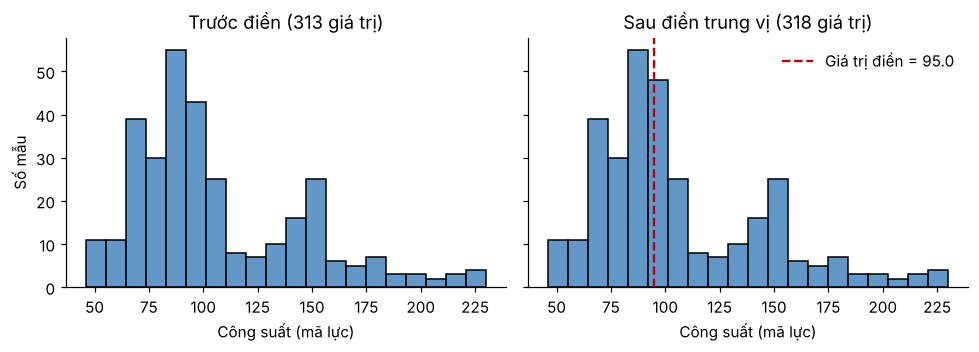

In [ ]:
hp = train["horsepower"]
hp_fill = hp.fillna(hp.median())          # chỉ để minh họa trước/sau; Pipeline sẽ làm việc này trong mỗi lần fit
def thong_ke(s):
    return {"Số giá trị": int(s.count()), "Trung bình": round(s.mean(), 2), "Độ lệch chuẩn": round(s.std(), 2),
            "Trung vị": s.median(), "Skew": round(s.skew(), 2)}
display(pd.DataFrame({"Trước điền": thong_ke(hp), "Sau điền": thong_ke(hp_fill)}))
print("Mẫu thiếu ở tập huấn luyện:"); print(train.loc[hp.isna(), ["name", "model_year", "origin"]].to_string())
print("Mẫu thiếu ở tập kiểm tra:"); print(test.loc[test["horsepower"].isna(), ["name", "model_year", "origin"]].to_string())

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3), sharey=True)
sns.histplot(hp.dropna(), bins=20, color="#2E75B6", ax=ax[0])
ax[0].set(title=f"Trước điền ({hp.count()} giá trị)", xlabel="Công suất (mã lực)", ylabel="Số mẫu")
sns.histplot(hp_fill, bins=20, color="#2E75B6", ax=ax[1])
ax[1].axvline(hp.median(), color="#C00000", ls="--", label=f"Giá trị điền = {hp.median():.1f}")
ax[1].set(title=f"Sau điền trung vị ({hp_fill.count()} giá trị)", xlabel="Công suất (mã lực)"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "hinh_2_7_truoc_sau_dien_thieu.png", dpi=150); plt.show()

**Nhận xét.** Tập huấn luyện thiếu 5 giá trị `horsepower`, tập kiểm tra thiếu 1 (ford pinto). Cách xử lý: **điền bằng trung vị 95,0 tính trên tập huấn luyện**, và dùng đúng giá trị đó cho mẫu thiếu ở tập kiểm tra. Lý do chọn trung vị: `horsepower` lệch phải (skew 1,04) nên trung vị ít bị kéo bởi các xe công suất lớn hơn trung bình. Không xóa dòng vì dữ liệu chỉ có 398 mẫu và các thuộc tính khác của những dòng này đầy đủ; tỷ lệ thiếu thấp (1,5%) nên các cách phức tạp hơn (điền theo KNN, hồi quy) không đáng đánh đổi.

Kiểm chứng trước – sau: trung bình đổi từ 105,95 xuống 105,77, độ lệch chuẩn từ 39,09 xuống 38,80, trung vị giữ nguyên 95,0, skew từ 1,04 lên 1,06. Hình dạng phân phối gần như không đổi (Hình 2.7), nên việc điền không làm méo dữ liệu.

## 3. Ngoại lai

In [ ]:
rows = []
for c in [TARGET] + NUM:
    q1, q3 = train[c].quantile([.25, .75]); lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)   # ngưỡng tính từ tập huấn luyện
    dem = lambda t: int(((t[c] < lo) | (t[c] > hi)).sum())
    rows.append({"Thuộc tính": c, "Ngưỡng dưới": round(lo, 1), "Ngưỡng trên": round(hi, 1),
                 "Ngoại lai (huấn luyện)": dem(train), "Ngoại lai (kiểm tra)": dem(test)})
pd.DataFrame(rows)

,Thuộc tính,Ngưỡng dưới,Ngưỡng trên,Ngoại lai (huấn luyện),Ngoại lai (kiểm tra)
0,mpg,-1.2,47.1,0,0
1,cylinders,-2.0,14.0,0,0
2,displacement,-190.5,597.5,0,0
3,horsepower,-5.0,211.0,7,1
4,weight,157.4,5732.4,0,0
5,acceleration,8.7,22.0,8,2
6,model_year,64.0,88.0,0,0


**Nhận xét.** Với ngưỡng IQR tính từ tập huấn luyện, `horsepower` có 7 ngoại lai ở tập huấn luyện và 1 ở tập kiểm tra (ngưỡng trên 211,0 mã lực), `acceleration` có 8 và 2 (ngoài khoảng 8,7–22,0 giây); các thuộc tính còn lại không có.

**Quyết định: giữ nguyên các ngoại lai.** Lý do: (1) Ở bước khảo sát đã đối chiếu tên xe, tất cả đều là xe có thật (xe Mỹ cỡ lớn, xe diesel chạy chậm, xe thể thao chạy nhanh), không phải lỗi nhập liệu. (2) Chúng nằm ở hai đầu miền giá trị, đúng vùng ít mẫu mà mô hình cần học; xóa đi sẽ làm mô hình kém khi gặp xe tương tự. (3) Các đặc trưng được chuẩn hóa và có thể dùng Ridge, nên ảnh hưởng của điểm xa được kiểm soát. Nếu phân tích lỗi ở Chương 3 cho thấy các điểm này gây sai số lớn thì sẽ xem lại (cắt theo ngưỡng IQR hoặc biến đổi log).

## 4. Mã hóa và chuẩn hóa bằng Pipeline (fit trên tập huấn luyện)

Cột sau biến đổi: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin_europe', 'origin_japan', 'origin_usa']
X_train (318, 9) | y_train (318,) | X_test (80, 9) | y_test (80,)


,TB (huấn luyện),Độ lệch chuẩn (huấn luyện),TB (kiểm tra),Độ lệch chuẩn (kiểm tra)
cylinders,-0.00,1.00,-0.22,0.90
displacement,0.00,1.00,-0.20,0.91
horsepower,-0.00,1.00,-0.19,0.91
weight,0.00,1.00,-0.19,0.95
acceleration,0.00,1.00,0.17,1.01
model_year,0.00,1.00,-0.02,0.98
origin_europe,0.18,0.38,0.18,0.38
origin_japan,0.20,0.40,0.20,0.40
origin_usa,0.63,0.48,0.62,0.48


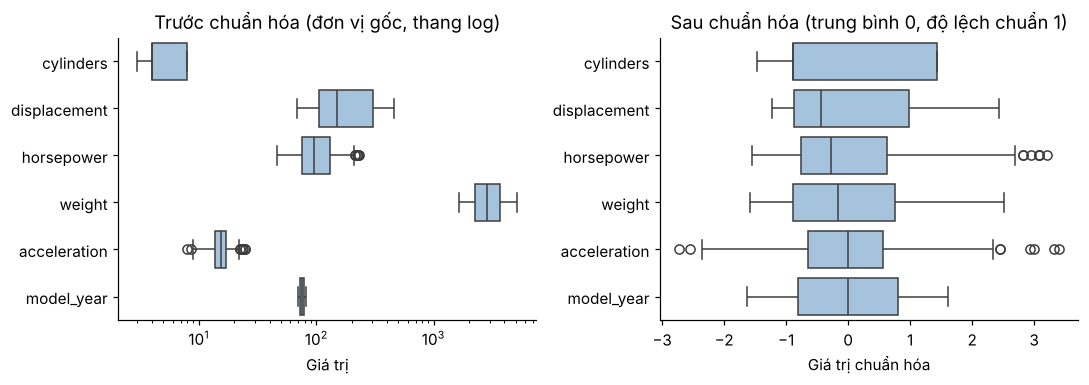

In [ ]:
pre = build_preprocessor()
pre.fit(train[NUM + CAT])                       # chỉ học từ tập huấn luyện
X_train, X_test = pre.transform(train[NUM + CAT]), pre.transform(test[NUM + CAT])
y_train, y_test = train[TARGET].to_numpy(), test[TARGET].to_numpy()
ten_cot = [n.split("__")[1] for n in pre.get_feature_names_out()]
print("Cột sau biến đổi:", ten_cot)
print("X_train", X_train.shape, "| y_train", y_train.shape, "| X_test", X_test.shape, "| y_test", y_test.shape)
display(pd.DataFrame({"TB (huấn luyện)": X_train.mean(0), "Độ lệch chuẩn (huấn luyện)": X_train.std(0),
                      "TB (kiểm tra)": X_test.mean(0), "Độ lệch chuẩn (kiểm tra)": X_test.std(0)}, index=ten_cot).round(2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
sns.boxplot(data=train[NUM], orient="h", color="#9DC3E6", ax=ax[0]); ax[0].set_xscale("log")
ax[0].set(title="Trước chuẩn hóa (đơn vị gốc, thang log)", xlabel="Giá trị")
sns.boxplot(data=pd.DataFrame(X_train[:, :len(NUM)], columns=NUM), orient="h", color="#9DC3E6", ax=ax[1])
ax[1].set(title="Sau chuẩn hóa (trung bình 0, độ lệch chuẩn 1)", xlabel="Giá trị chuẩn hóa")
plt.tight_layout(); plt.savefig(FIG / "hinh_2_8_truoc_sau_chuan_hoa.png", dpi=150); plt.show()

**Nhận xét.** Đầu ra có 9 cột: 6 đặc trưng số đã điền thiếu và chuẩn hóa, cộng 3 cột one-hot cho `origin` (europe, japan, usa). `origin` được one-hot vì không có thứ tự tự nhiên giữa các xuất xứ, và `handle_unknown="ignore"` phòng trường hợp gặp nhóm lạ. `cylinders` giữ dạng số vì có thứ tự và nhóm 3, 5 xi-lanh hiếm; one-hot sẽ tạo ra các cột gần như toàn 0.

Trên tập huấn luyện, các đặc trưng số có trung bình 0 và độ lệch chuẩn 1, đúng theo thiết kế. Trên tập kiểm tra, trung bình của `cylinders`, `displacement`, `horsepower`, `weight` lệch khoảng −0,2 độ lệch chuẩn (xe ở tập kiểm tra nhỏ và nhẹ hơn một chút) và `acceleration` lệch +0,17, tức không đúng 0. Đó là bằng chứng bộ chuẩn hóa chỉ học từ tập huấn luyện chứ không nhìn thấy tập kiểm tra. Hình 2.8 cho thấy trước chuẩn hóa các đặc trưng có thang đo chênh nhau hàng nghìn lần (weight so với cylinders), điều này sẽ làm Ridge và KNN thiên về đặc trưng có số lớn.

## 5. Kiểm tra rò rỉ dữ liệu

In [ ]:
imp = pre.named_transformers_["num"].named_steps["simpleimputer"]
i = NUM.index("horsepower")
print("Trung vị horsepower dùng để điền:", imp.statistics_[i], "| trung vị toàn bộ dữ liệu:", df["horsepower"].median())
thieu_test = test["horsepower"].isna().to_numpy()
print("Giá trị điền cho mẫu thiếu ở tập kiểm tra:", imp.transform(test[NUM])[thieu_test, i])

assert imp.statistics_[i] == train["horsepower"].median()          # học từ tập huấn luyện
assert imp.statistics_[i] != df["horsepower"].median()             # không phải từ toàn bộ dữ liệu
assert np.allclose(X_train[:, :len(NUM)].mean(0), 0, atol=1e-9)    # huấn luyện đã chuẩn hóa
assert not np.allclose(X_test[:, :len(NUM)].mean(0), 0, atol=0.05) # kiểm tra không bị chuẩn hóa theo chính nó
print("Các kiểm tra rò rỉ đều đạt.")

Trung vị horsepower dùng để điền: 95.0 | trung vị toàn bộ dữ liệu: 93.5
Giá trị điền cho mẫu thiếu ở tập kiểm tra: [95.]
Các kiểm tra rò rỉ đều đạt.


**Nhận xét.** Trung vị dùng để điền là 95,0 (tính từ tập huấn luyện), khác trung vị toàn bộ dữ liệu là 93,5. Nếu điền trước khi chia tập, giá trị 93,5 sẽ mang thông tin của tập kiểm tra vào huấn luyện. Mẫu thiếu ở tập kiểm tra được điền đúng 95,0. Toàn bộ phép biến đổi nằm trong Pipeline (`src/preprocess.py`) nên khi kiểm định chéo ở Chương 3, mỗi fold sẽ tự khớp lại trên phần huấn luyện của chính nó.

## 6. Bảng tổng hợp: vấn đề – cách xử lý – lý do

In [ ]:
q = lambda s: s.quantile([.25, .75])
tong_hop = pd.DataFrame([
    ["Giá trị thiếu (horsepower: 6 mẫu)", "Điền trung vị tính trên tập huấn luyện (95,0), nằm trong Pipeline",
     "Lệch phải (skew 1,04) nên trung vị bền hơn trung bình; dữ liệu ít nên không xóa dòng",
     f"Trung bình {hp.mean():.2f} -> {hp_fill.mean():.2f}; độ lệch chuẩn {hp.std():.2f} -> {hp_fill.std():.2f}; trung vị giữ {hp.median()}"],
    ["Ngoại lai (mpg 1, horsepower 10, acceleration 7)", "Giữ nguyên",
     "Là xe thật, nằm ở hai đầu miền giá trị; Ridge và chuẩn hóa kiểm soát ảnh hưởng",
     "Ngoại lai theo ngưỡng tính từ huấn luyện: horsepower 7/1, acceleration 8/2 (huấn luyện/kiểm tra)"],
    ["Bản ghi trùng", "Không có dòng trùng nên không xử lý", "0 dòng trùng hoàn toàn, 0 dòng trùng khi bỏ cột name", "duplicated() = 0"],
    ["Sai định dạng", "Không có nên không xử lý", "Cột số đúng kiểu số, không có giá trị không hợp lý", "Đã kiểm tra ở notebook 01"],
    ["Tên xe lặp (93 dòng) và nguy cơ rò rỉ do name", "Gom theo name khi chia tập; không dùng name làm đặc trưng",
     "Tránh cùng một kiểu xe nằm ở cả hai tập", f"Tên xe chung giữa hai tập: {len(shared)}"],
    ["Mất cân bằng origin, cylinders hiếm", "Chia phân tầng theo origin; cylinders giữ dạng số",
     "Giữ tỷ lệ xuất xứ ở hai tập; one-hot cylinders tạo cột gần toàn 0", "usa 62,6% / 62,5%; 3 và 5 xi-lanh: 5 mẫu huấn luyện, 2 mẫu kiểm tra"],
    ["Biến phân loại origin", "One-hot 3 cột", "Không có thứ tự tự nhiên giữa các xuất xứ", f"X_train có {X_train.shape[1]} cột"],
    ["Khác thang đo, lệch phân phối", "StandardScaler fit trên tập huấn luyện", "Ridge và KNN nhạy với thang đo",
     "Huấn luyện: TB 0, độ lệch chuẩn 1; kiểm tra: TB khoảng −0,2 (không rò rỉ)"],
    ["Đa cộng tuyến (VIF 9–20)", "Chưa xử lý ở bước này", "Xử lý bằng Ridge và chọn tập đặc trưng ở Chương 3", "VIF từ notebook 01"],
], columns=["Vấn đề", "Cách xử lý", "Lý do", "Kiểm chứng"])
tong_hop.to_csv("../reports/bang_xu_ly_du_lieu.csv", index=False, encoding="utf-8-sig")
pd.set_option("display.max_colwidth", 120); tong_hop

,Vấn đề,Cách xử lý,Lý do,Kiểm chứng
0,Giá trị thiếu (horsepower: 6 mẫu),"Điền trung vị tính trên tập huấn luyện (95,0), nằm trong Pipeline","Lệch phải (skew 1,04) nên trung vị bền hơn trung bình; dữ liệu ít nên không xóa dòng",Trung bình 105.95 -> 105.77; độ lệch chuẩn 39.09 -> 38.80; trung vị giữ 95.0
1,"Ngoại lai (mpg 1, horsepower 10, acceleration 7)",Giữ nguyên,"Là xe thật, nằm ở hai đầu miền giá trị; Ridge và chuẩn hóa kiểm soát ảnh hưởng","Ngoại lai theo ngưỡng tính từ huấn luyện: horsepower 7/1, acceleration 8/2 (huấn luyện/kiểm tra)"
2,Bản ghi trùng,Không có dòng trùng nên không xử lý,"0 dòng trùng hoàn toàn, 0 dòng trùng khi bỏ cột name",duplicated() = 0
3,Sai định dạng,Không có nên không xử lý,"Cột số đúng kiểu số, không có giá trị không hợp lý",Đã kiểm tra ở notebook 01
4,Tên xe lặp (93 dòng) và nguy cơ rò rỉ do name,Gom theo name khi chia tập; không dùng name làm đặc trưng,Tránh cùng một kiểu xe nằm ở cả hai tập,Tên xe chung giữa hai tập: 0
5,"Mất cân bằng origin, cylinders hiếm",Chia phân tầng theo origin; cylinders giữ dạng số,Giữ tỷ lệ xuất xứ ở hai tập; one-hot cylinders tạo cột gần toàn 0,"usa 62,6% / 62,5%; 3 và 5 xi-lanh: 5 mẫu huấn luyện, 2 mẫu kiểm tra"
6,Biến phân loại origin,One-hot 3 cột,Không có thứ tự tự nhiên giữa các xuất xứ,X_train có 9 cột
7,"Khác thang đo, lệch phân phối",StandardScaler fit trên tập huấn luyện,Ridge và KNN nhạy với thang đo,"Huấn luyện: TB 0, độ lệch chuẩn 1; kiểm tra: TB khoảng −0,2 (không rò rỉ)"
8,Đa cộng tuyến (VIF 9–20),Chưa xử lý ở bước này,Xử lý bằng Ridge và chọn tập đặc trưng ở Chương 3,VIF từ notebook 01
